## 1. Setup

In [28]:
import sys, json, re, warnings, inspect
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.append(str(Path.cwd().parent))          # make the `src` package importable
from src.data import LABELS, load_airline, make_split
from src.preprocess import clean_tweet, ensure_nltk, URL_RE, MENTION_RE
from src.evaluate import evaluate, plot_confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ensure_nltk()

ROOT = Path.cwd().parent
DATA_PATH = ROOT / "data" / "raw" / "Tweets.csv"
PROC_DIR, MODELS_DIR, REPORTS_DIR = ROOT / "data" / "processed", ROOT / "models", ROOT / "reports"
for d in (PROC_DIR, MODELS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

COLORS = {"negative": "#e15759", "neutral": "#9d9da1", "positive": "#59a14f"}

## 2. Load the data

In [29]:
df = load_airline(DATA_PATH)       # keeps label/text/timestamp/airline, drops duplicate tweets
print("Shape:", df.shape)
df.head()

Shape: (14427, 4)


,label,text,tweet_created,airline
0,neutral,@VirginAmerica What @dhepburn said.,2015-02-24 11:35:52 -0800,Virgin America
1,positive,@VirginAmerica plus you've added commercials to the experience... tacky.,2015-02-24 11:15:59 -0800,Virgin America
2,neutral,@VirginAmerica I didn't today... Must mean I need to take another trip!,2015-02-24 11:15:48 -0800,Virgin America
3,negative,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they ...",2015-02-24 11:15:36 -0800,Virgin America
4,negative,@VirginAmerica and it's a really big bad thing about it,2015-02-24 11:14:45 -0800,Virgin America


## 3. Exploratory data analysis

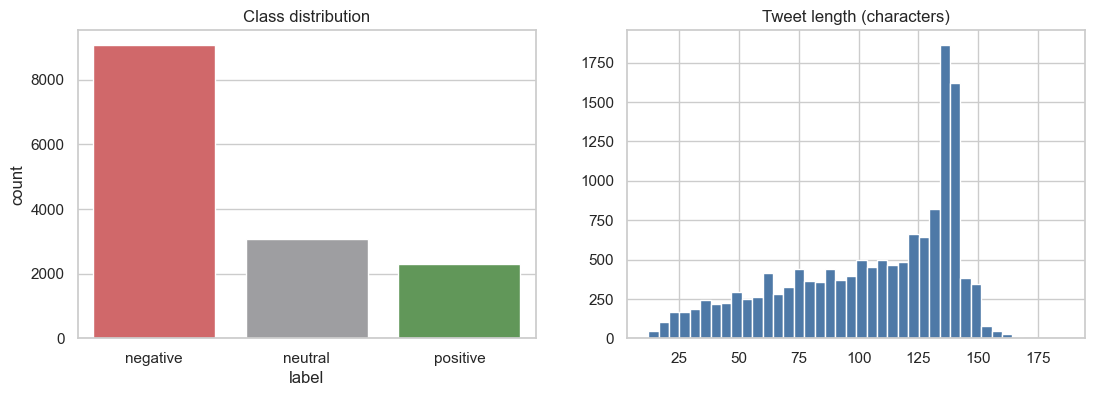

label
negative    0.629
neutral     0.212
positive    0.159
Name: proportion, dtype: float64


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="label", hue="label", order=LABELS, palette=COLORS, legend=False, ax=axes[0])
axes[0].set_title("Class distribution")
df["text"].str.len().hist(bins=40, ax=axes[1], color="#4e79a7")
axes[1].set_title("Tweet length (characters)")
plt.show()
print(df["label"].value_counts(normalize=True).round(3))

The classes are **imbalanced** (negative dominates), so accuracy alone is misleading. We therefore report **macro** precision/recall/F1 and use `class_weight="balanced"` where possible.

## 4. Cleaning pipeline
The full implementation lives in `src/preprocess.py` so that the notebooks and the Streamlit app use *identical* cleaning.

Steps: **normalise** (lowercase, HTML entities) -> **noise removal** (URLs, @mentions, `#` symbol, digits, punctuation, emojis, repeated letters)
-> **linguistic processing** (stop-word removal + lemmatization). Negations ("not", "no", "never") are deliberately **kept** because they flip sentiment.

In [31]:
print(inspect.getsource(clean_tweet))

def clean_tweet(text, lemmatize=True, remove_stopwords=True, keep_hashtag_words=True):
    """Clean a raw tweet and return a space-separated string of tokens.

    Parameters
    ----------
    lemmatize : convert words to their dictionary form.
    remove_stopwords : drop common words (negations are always kept).
        Use False for sequence models (LSTM) so word order/context is preserved.
    keep_hashtag_words : "#fail" -> "fail" (True) or remove the whole hashtag (False).
    """
    if not isinstance(text, str):
        return ""

    # 1. Normalisation
    text = html.unescape(text).lower().replace("\u2019", "'")

    # 2. Noise removal
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HASHTAG_RE.sub(r"\1" if keep_hashtag_words else " ", text)
    for pattern, repl in CONTRACTIONS:
        text = re.sub(pattern, repl, text)
    text = REPEAT_RE.sub(r"\1\1", text)
    text = NON_ALPHA_RE.sub(" ", text)          # digits, punctuation, emojis

    t

In [32]:
demo = "@united I've been waiting 4 hours!!! sooo annoyed #fail http://t.co/abc123 no refund"
t = demo.lower();                    print("1 lowercase      :", t)
t = URL_RE.sub(" ", t);              print("2 strip URLs     :", t)
t = MENTION_RE.sub(" ", t);          print("3 strip mentions :", t)
t = re.sub(r"#(\w+)", r"\1", t);     print("4 hashtags       :", t)
print("5 full pipeline  :", clean_tweet(demo))
print()
print("Lemmatization    :", clean_tweet("running flies delayed bags were lost"))

1 lowercase      : @united i've been waiting 4 hours!!! sooo annoyed #fail http://t.co/abc123 no refund
2 strip URLs     : @united i've been waiting 4 hours!!! sooo annoyed #fail   no refund
3 strip mentions :   i've been waiting 4 hours!!! sooo annoyed #fail   no refund
4 hashtags       :   i've been waiting 4 hours!!! sooo annoyed fail   no refund
5 full pipeline  : wait hour soo annoy fail no refund

Lemmatization    : run fly delay bag lose


In [33]:
pd.set_option("display.max_colwidth", 110)
sample = df.sample(6, random_state=7)[["text"]].copy()
sample["clean_text"] = sample["text"].apply(clean_tweet)
sample

,text,clean_text
3022,@united what's the point of offering a free checked bag of you lose it?,point offer free check bag lose
13135,@AmericanAir got off the phone w/ rep now flight has disappeared. Locator IRRLCD she said I was reschedule...,get off phone rep flight disappear locator irrlcd say reschedule help please
13202,@AmericanAir it has been almost 4 hours and I have heard nothing yet from your reservations team. What am ...,almost hour hear nothing yet reservation team suppose
11676,@USAirways I'm traveling around the world until the end of the year. 800 numbers do me no good.,travel around world end year number no good
2978,@united just sent - thank you!,send thank
2143,@united please get me off this plane #UA57,please get off plane ua


## 5. Train / test split, then clean
We split the **raw** data first (stratified 80/20, fixed seed). Notebook 02 uses the same split, so both models are scored on exactly the same test tweets.

In [34]:
train_df, test_df = make_split(df)
train_df, test_df = train_df.copy(), test_df.copy()

train_df["clean_text"] = train_df["text"].apply(clean_tweet)
test_df["clean_text"] = test_df["text"].apply(clean_tweet)

print("Train:", train_df.shape, " Test:", test_df.shape)
print("Tweets that became empty after cleaning:", (train_df["clean_text"] == "").sum())

pd.concat([train_df.assign(split="train"), test_df.assign(split="test")]).to_csv(
    PROC_DIR / "tweets_clean.csv", index=False)
train_df[["text", "clean_text", "label"]].head()

Train: (11541, 5)  Test: (2886, 5)
Tweets that became empty after cleaning: 11


,text,clean_text,label
7624,@JetBlue no. Not boarding order. Someone boarded with. Service Animal which a member of my party was aller...,no not board order someone board service animal member party allergic flight,negative
9783,"@USAirways sucks. Delayed my mom's flight 2X, Cancelled Flightled it, delayed her flight again today,all f...",suck delay mom flight cancel flightled delay flight today mech issue sleep airport,negative
7088,RT @JetBlue: Our fleet's on fleek. http://t.co/826Pkiq5HI,rt fleet fleek,neutral
2157,"@united when I read it say ' in some cases' can you please define this for me, when for example would it n...",read say case please define example would not case,negative
12118,@AmericanAir I am dealing with the reFlight Booking Problems agent in the Miami airport now,deal reflight book problem agent miami airport,neutral


## 6. Word frequency & word clouds (training data only)

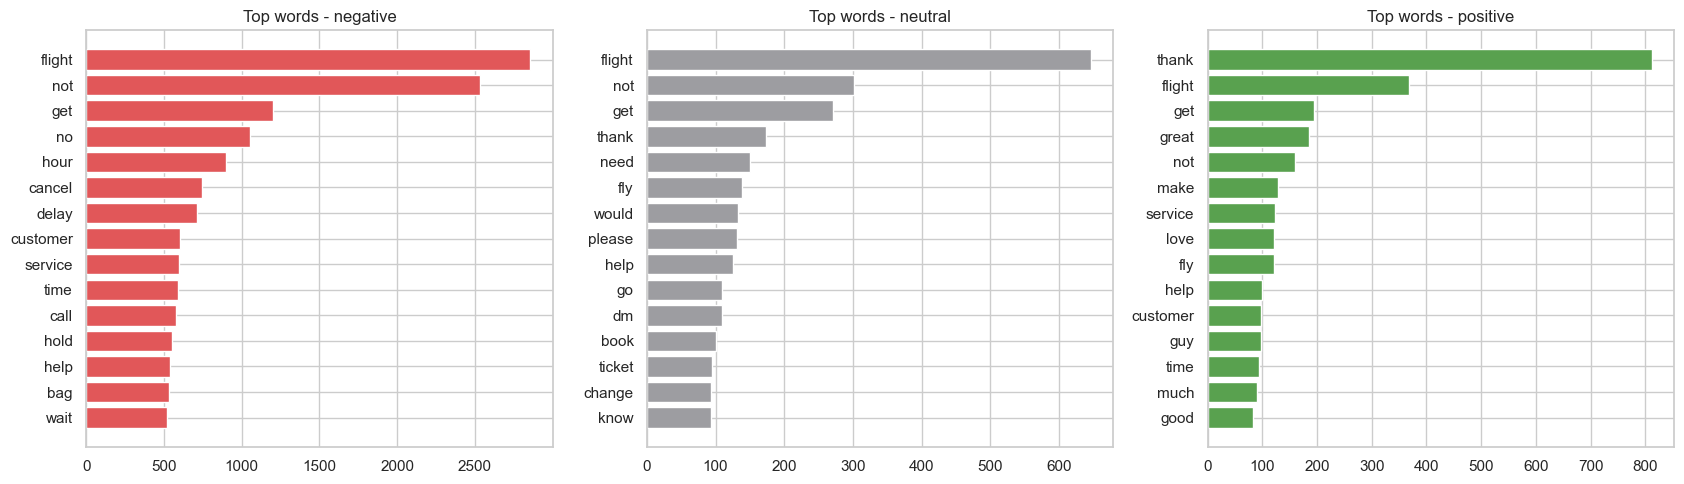

In [35]:
def top_words(series, n=15):
    return Counter(" ".join(series).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, lab in zip(axes, LABELS):
    words, counts = zip(*top_words(train_df.loc[train_df.label == lab, "clean_text"]))
    ax.barh(words[::-1], counts[::-1], color=COLORS[lab])
    ax.set_title(f"Top words - {lab}")
plt.tight_layout(); plt.show()

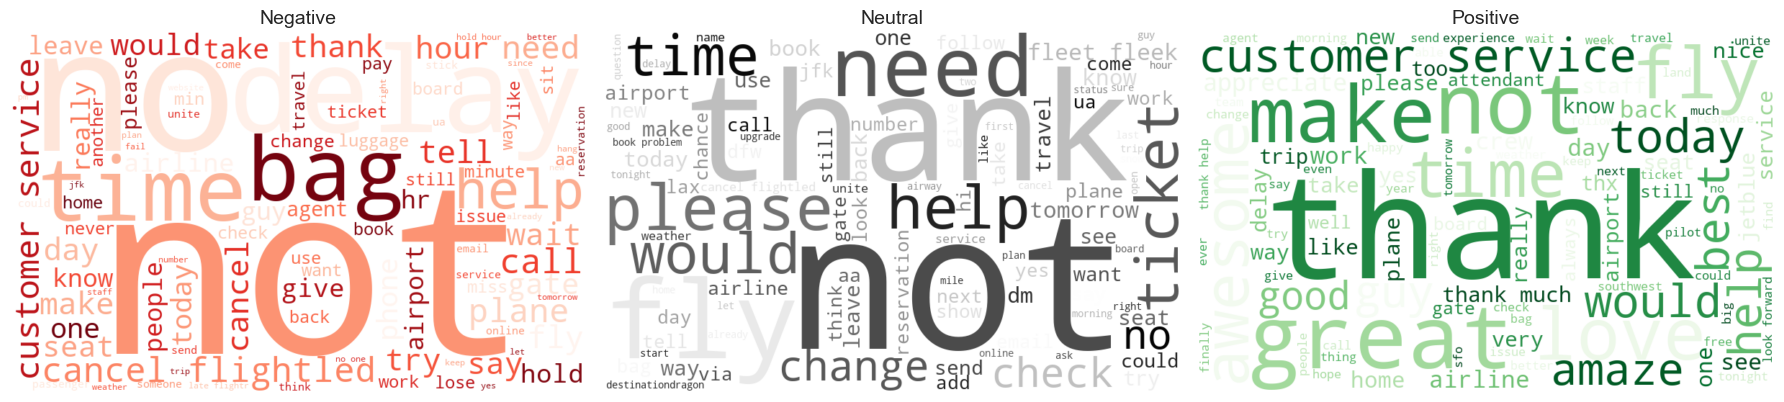

In [36]:
from wordcloud import WordCloud

generic = {"flight", "get", "amp", "go", "u"}     # words that appear in every class
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab, cmap in zip(axes, LABELS, ["Reds", "Greys", "Greens"]):
    text = " ".join(train_df.loc[train_df.label == lab, "clean_text"])
    wc = WordCloud(width=800, height=500, background_color="white", colormap=cmap,
                   max_words=100, stopwords=generic).generate(text)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(lab.title(), fontsize=14)
plt.tight_layout()
fig.savefig(REPORTS_DIR / "wordclouds.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Feature engineering - TF-IDF
TF-IDF scores a word high when it is frequent **in this tweet** but rare **across all tweets**, so keywords such as "delayed" or "rude" stand out while filler words are down-weighted.
We use unigrams + bigrams (so "not good" becomes its own feature) and sub-linear term frequency.

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)
X_demo = tfidf.fit_transform(train_df["clean_text"])
print("Matrix shape :", X_demo.shape, "(tweets x features)")
print("Sparsity     : {:.2%} zeros".format(1 - X_demo.nnz / np.prod(X_demo.shape)))

idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("\nMost common (lowest IDF):", list(idf.index[:8]))
print("Rarest (highest IDF)    :", list(idf.index[-8:]))

Matrix shape : (11541, 13677) (tweets x features)
Sparsity     : 99.91% zeros

Most common (lowest IDF): ['flight', 'not', 'get', 'thank', 'no', 'hour', 'cancel', 'service']
Rarest (highest IDF)    : ['aa ord', 'aa number', 'zero entertainment', 'zero response', 'aa email', 'zoom', 'aa cancel', 'aa ba']


## 8. Train classical models

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

def make_pipe(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)),
        ("clf", clf),
    ])

X_train, y_train = train_df["clean_text"], train_df["label"]
X_test, y_test = test_df["clean_text"], test_df["label"]

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, C=2, class_weight="balanced")),
    "Naive Bayes":         make_pipe(MultinomialNB(alpha=0.5)),
    "Linear SVM":          make_pipe(LinearSVC(C=0.5, class_weight="balanced")),
}

results, preds = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds[name] = pipe.predict(X_test)
    results.append(evaluate(y_test, preds[name], name))

pd.DataFrame(results).set_index("Model")

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.7775,0.7175,0.7405,0.7279
Naive Bayes,0.7356,0.7681,0.5474,0.5883
Linear SVM,0.7890,0.7328,0.7248,0.7286


### Hyper-parameter tuning (Logistic Regression)

In [39]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced")),
    param_grid={"clf__C": [0.5, 1, 2, 5, 10], "tfidf__ngram_range": [(1, 1), (1, 2)]},
    scoring="f1_macro", cv=3, n_jobs=-1,
)
grid.fit(X_train, y_train)
print("Best params :", grid.best_params_)
print("CV macro-F1 : {:.4f}".format(grid.best_score_))

best = grid.best_estimator_
preds["Logistic Regression (tuned)"] = best.predict(X_test)
results.append(evaluate(y_test, preds["Logistic Regression (tuned)"], "Logistic Regression (tuned)"))

Best params : {'clf__C': 1, 'tfidf__ngram_range': (1, 2)}
CV macro-F1 : 0.7162


## 9. Evaluation

In [40]:
from sklearn.metrics import classification_report

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.style.highlight_max(color="#c6efce"))

print(classification_report(y_test, preds["Logistic Regression (tuned)"], digits=3))

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.777500,0.717500,0.740500,0.727900
Naive Bayes,0.735600,0.768100,0.547400,0.588300
Linear SVM,0.789000,0.732800,0.724800,0.728600
Logistic Regression (tuned),0.778900,0.720600,0.747000,0.732200


              precision    recall  f1-score   support

    negative      0.887     0.826     0.855      1816
     neutral      0.570     0.649     0.607       612
    positive      0.705     0.766     0.734       458

    accuracy                          0.779      2886
   macro avg      0.721     0.747     0.732      2886
weighted avg      0.791     0.779     0.783      2886



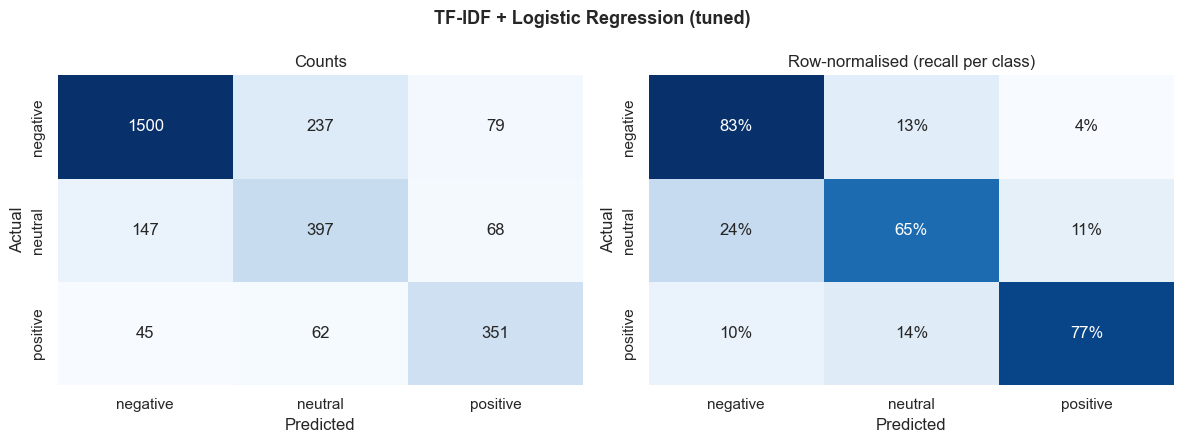

In [41]:
fig = plot_confusion_matrix(y_test, preds["Logistic Regression (tuned)"], LABELS,
                            "TF-IDF + Logistic Regression (tuned)",
                            save_path=REPORTS_DIR / "cm_classical.png")
plt.show()

**Reading the matrix:** the diagonal is correct predictions. The *neutral* class is usually the hardest (it is small and its vocabulary overlaps with both other classes).
Sarcasm is also a weak spot for bag-of-words models: "Thanks for losing my bag" contains positive words but is negative.

## 10. Interpretability - why did the model decide that?

In [42]:
vec, clf = best.named_steps["tfidf"], best.named_steps["clf"]
features = np.array(vec.get_feature_names_out())

rows = {}
for i, lab in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[-12:][::-1]
    rows[lab] = list(features[top])
pd.DataFrame(rows)

,negative,neutral,positive
0,not,hi,thank
1,hour,dm,great
2,delay,question,love
3,no,delay cancel,awesome
4,hold,carry,amaze
5,worst,avgeek,best
6,bag,policy,thx
7,hr,no not,not wait
8,nothing,possible,appreciate
9,lose,chance,kudos


## 11. Error analysis

In [43]:
errors = test_df.assign(pred=preds["Logistic Regression (tuned)"])
errors = errors[errors["label"] != errors["pred"]]
print(f"{len(errors)} misclassified of {len(test_df)} ({len(errors)/len(test_df):.1%})")
errors[["text", "label", "pred"]].sample(min(10, len(errors)), random_state=1)

638 misclassified of 2886 (22.1%)


,text,label,pred
11394,@USAirways would be more pleased if you reassess your business practices. Goal should be to have passenge...,negative,neutral
8773,@jetblue is there no way to switch to earlier flight to JFK even if I checked a bag?,neutral,negative
6053,@SouthwestAir I ❤️ you! The only airline that understands us military families and our unpredictable chang...,positive,negative
14144,@AmericanAir you have such a confusing web site/complicated ordering process. This is why I typically fly ...,negative,neutral
6490,@southwestair TREMENDOUS job. Atlanta Airport saw SW celebrate Mardi Gras. Another reason I'm nuts for you...,neutral,positive
11547,@USAirways my sister was supposed to leave at 10 am to go back to AL. She's only getting to NC now. Are yo...,negative,neutral
7112,@JetBlue I just booked a flight with you guys. I'm reconsidering that decision now after reading this tweet.,negative,neutral
8950,@USAirways I have two tight connections in #Charlotte and #Frankfurt,negative,neutral
10636,@USAirways I'm dumping this dividend miles card and forgetting your airline exists #ridiculous #theworstai...,negative,neutral
5786,@SouthwestAir please do something about the speed of your WiFi connections on your planes. It might as we...,negative,neutral


## 12. Custom inference

In [44]:
def predict_sentiment(texts, model=best):
    cleaned = [clean_tweet(t) for t in texts]
    proba = model.predict_proba(cleaned)
    out = pd.DataFrame(proba, columns=model.classes_).round(3)
    out.insert(0, "prediction", model.classes_[proba.argmax(1)])
    out.insert(0, "text", texts)
    return out

predict_sentiment([
    "The service was amazing!",
    "I waited 4 hours just to get a cold burger.",
    "Does anyone know the baggage allowance for international flights?",
    "Oh great, another delayed flight. Just what I needed.",      # sarcasm
    "Not happy with the delay but the crew was very helpful.",    # mixed
])

,text,prediction,negative,neutral,positive
0,The service was amazing!,positive,0.019,0.022,0.960
1,I waited 4 hours just to get a cold burger.,negative,0.882,0.061,0.057
2,Does anyone know the baggage allowance for international flights?,neutral,0.131,0.805,0.064
3,"Oh great, another delayed flight. Just what I needed.",negative,0.686,0.098,0.216
4,Not happy with the delay but the crew was very helpful.,positive,0.490,0.007,0.504


## 13. Save artefacts for the dashboard and the final report

In [45]:
joblib.dump(best, MODELS_DIR / "tfidf_logreg.joblib")
(REPORTS_DIR / "classical_results.json").write_text(json.dumps(results, indent=2))
print("Saved:", [p.name for p in MODELS_DIR.glob("*")], [p.name for p in REPORTS_DIR.glob("*")])

Saved: ['tfidf_logreg.joblib'] ['classical_results.json', 'cm_classical.png', 'wordclouds.png']


---
### Optional: using Sentiment140 instead
Sentiment140 (`training.1600000.processed.noemoticon.csv`) has no header, `latin-1` encoding and columns `target, id, date, flag, user, text` with `target` in {0 = negative, 4 = positive}:
```python
cols = ["target", "id", "date", "flag", "user", "text"]
df = pd.read_csv(path, encoding="latin-1", names=cols)
df["label"] = df["target"].map({0: "negative", 4: "positive"})
df = df.sample(200_000, random_state=42)      # subsample: 1.6M rows is slow for the LSTM
```
Note that it only has two classes, so "neutral" would have to be dropped from `LABELS`.